11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 50s 29ms/step - accuracy: 0.9560 - loss: 0.1462 - val_accuracy: 0.9845 - val_loss: 0.0511
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 46s 28ms/step - accuracy: 0.9849 - loss: 0.0485 - val_accuracy: 0.9867 - val_loss: 0.0453
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 84s 29ms/step - accuracy: 0.9895 - loss: 0.0333 - val_accuracy: 0.9888 - val_loss: 0.0422
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 47s 28ms/step - accuracy: 0.9919 - loss: 0.0247 - val_accuracy: 0.9905 - val_loss: 0.0369
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 82s 28ms/step - accuracy: 0.9942 - loss: 0.0183 - val_accuracy: 0.9897 - val_loss: 0.0355
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9906 - loss: 0.0283

Test accuracy: 0.9905999898910522
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


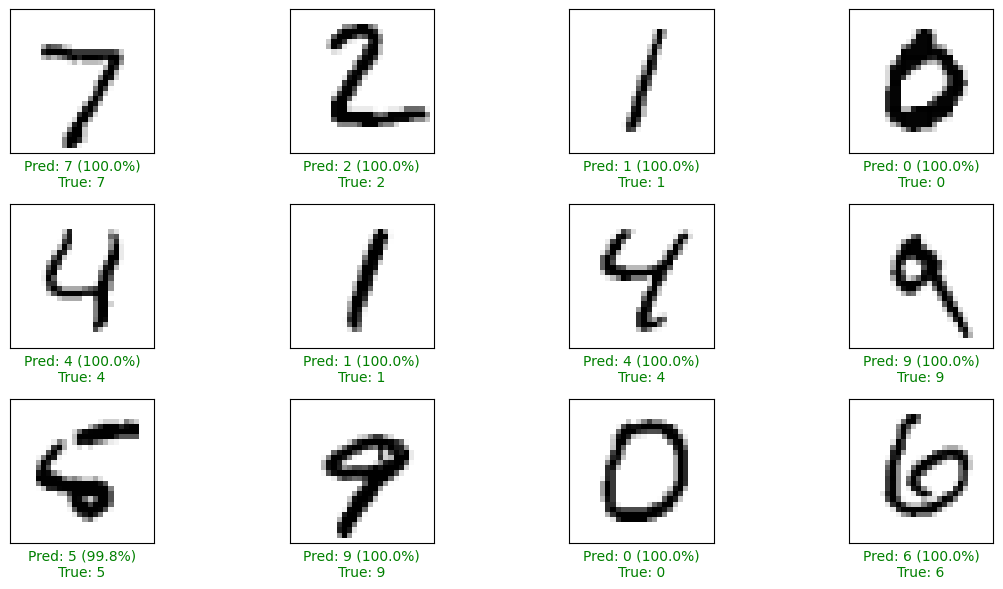

In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt


(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()


x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0


x_train = x_train[..., tf.newaxis]
x_test = x_test[..., tf.newaxis]


model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])


model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


history = model.fit(x_train, y_train, epochs=5, validation_split=0.1)


test_loss, test_acc = model.evaluate(x_test, y_test)
print("\nTest accuracy:", test_acc)

predictions = model.predict(x_test)


def plot_digit(i, predictions_array, true_label, img):
    predictions_array, true_label, img = predictions_array[i], true_label[i], img[i]
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])

    plt.imshow(img.squeeze(), cmap=plt.cm.binary)

    predicted_label = predictions_array.argmax()
    if predicted_label == true_label:
        color = 'green'
    else:
        color = 'red'

    plt.xlabel(f"Pred: {predicted_label} ({100*np.max(predictions_array):.1f}%)\nTrue: {true_label}", color=color)


import numpy as np
num_rows = 3
num_cols = 4
plt.figure(figsize=(12,6))
for i in range(num_rows * num_cols):
    plt.subplot(num_rows, num_cols, i+1)
    plot_digit(i, predictions, y_test, x_test)
plt.tight_layout()
plt.show()